In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import matplotlib.pyplot as plt
from kloppy import metrica


import games
import time

paths = games.asset_paths(source='tactical')

# Summary of Changes and observations

- Observation: Ball speed is present in atd file, has some entries with values but in frame_df all values are empty. Kloppy metrica doesn't include the field, we created own reader for speed and merged it with frame_df
- Observation: Players have: x, y, d and s. D field is not present in file and all values are empty.
- Observation: Players info we have 22 players on the pitch. But tracker has 46 trackers. As commented in the data description:  "Slots appear, vanish and swap identity as the tracker loses and re-acquires people. Expect around 22 tracked objects during play — the mean over graded frames is 20.5, and it occasionally exceeds 22 when the tracker duplicates someone. You get positions and team membership, nothing more, so any analysis you build has to be collective rather than per-player". Strategies to relign players by positions, check duplicates when we have more than 22 players might be usefull. Also file marks slots:  24 y el 46 as Goalkeeper. Others as unknown. 

# Conclusions

- Ball speed read from the file doesn't seem to apport extra information. Ball speed ms is computed from ball position comparing, prev frame position if exist with current.

## Match Related Info

- https://www.fcbarcelona.es/es/partidos/116220/fc-barcelona-athletic-club-la-liga-2024-2025
- https://www.laliga.com/partido/temporada-2024-2025-laliga-ea-sports-fc-barcelona-athletic-club-2

## Radu review ideas

- Duplicated pos for players are just 2000 frames or less during match, review if this can help us improve
- Ball speed was geenrated it from ball position from on frame compared with previous. So missin balls if we have the speed we can check if its out of the field. just an estimator. Detectar fueras de campo de la pelota.

## Read full dataset evaluation:

In [2]:
t0 = time.perf_counter()
dataset = metrica.load_tracking_epts(
    meta_data=paths["atd_meta"],
    raw_data=paths["atd_raw"],
)
elapsed = time.perf_counter() - t0
print("%d frames in %.1f s" % (len(dataset.records), elapsed))

199319 frames in 26.9 s


199319 frames in 26.7 s

In [6]:
t1 = time.perf_counter()
frame_df = dataset.to_df()
elapsed = time.perf_counter() - t1
print("%d frames in %s s" % (frame_df.shape[0], elapsed))

199319 frames in 8.829015916911885 s


## Ball speed

In [7]:
def load_ball_speed(raw_path, n_frames):
    """Ball speed from the raw ATD, in the unit the XML declares (kph).

    The ball is the third ':' field of each line, and speed is its third comma
    value. Kloppy drops that value, so this reads the text directly. Index i is
    video frame i. NaN where the file has no speed.
    """
    speed = np.full(n_frames, np.nan)
    with open(raw_path) as handle:
        for line in handle:
            frame, _, ball = line.split(":", 2)
            value = ball.rstrip("\n").split(",")[2]
            if value != "NaN":
                speed[int(frame) - 1] = float(value)
    return speed


ball_speed = load_ball_speed(paths["atd_raw"], games.GAMES[games.GAME]["n_video_frames"])
print("numeric speeds: %d of %d" % (np.isfinite(ball_speed).sum(), len(ball_speed)))

# frame_id starts at 1; ball_speed[i] is video frame i.
frame_df["ball_speed"] = ball_speed[frame_df["frame_id"].to_numpy() - 1]
frame_df["ball_speed"].value_counts(dropna=False)

numeric speeds: 20971 of 199319


ball_speed
NaN         178348
1.387768         2
1.191529         2
0.545196         2
1.074279         2
             ...  
1.293019         1
1.267769         1
1.236331         1
1.198929         1
1.155892         1
Name: count, Length: 20968, dtype: int64

In [8]:
frame_df

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,NaN,0.33411,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,NaN,0.33404,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,NaN,0.33396,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
3,1,0 days 00:00:00.160000,4,None,None,NaN,NaN,None,NaN,0.33389,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4,1,0 days 00:00:00.200000,5,None,None,NaN,NaN,None,NaN,0.33382,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199314,1,0 days 02:12:52.600000,199315,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
199315,1,0 days 02:12:52.640000,199316,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
199316,1,0 days 02:12:52.680000,199317,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
199317,1,0 days 02:12:52.720000,199318,None,None,NaN,NaN,None,NaN,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN


In [9]:
round((frame_df[frame_df["ball_x"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)

56.94

In [10]:
round((frame_df[frame_df["ball_y"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)

56.94

In [11]:
frame_df[(frame_df["ball_x"].isna() == False) & (frame_df["ball_y"].isna() != False)]

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s


In [12]:
frame_df[(frame_df["ball_x"].isna() != False) & (frame_df["ball_y"].isna() == False)]

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s


In [13]:
frame_df[frame_df["ball_speed"].isna() == False]

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
4817,1,0 days 00:03:12.720000,4818,None,None,NaN,NaN,None,1.495544,NaN,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4818,1,0 days 00:03:12.760000,4819,None,None,NaN,NaN,None,1.503945,NaN,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4819,1,0 days 00:03:12.800000,4820,None,None,NaN,NaN,None,1.514737,NaN,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4820,1,0 days 00:03:12.840000,4821,None,None,NaN,NaN,None,1.528223,NaN,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
4821,1,0 days 00:03:12.880000,4822,None,None,NaN,NaN,None,1.544720,NaN,...,None,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
194375,1,0 days 02:09:35.040000,194376,None,None,NaN,NaN,None,1.293019,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
194376,1,0 days 02:09:35.080000,194377,None,None,NaN,NaN,None,1.267769,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
194377,1,0 days 02:09:35.120000,194378,None,None,NaN,NaN,None,1.236331,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN
194378,1,0 days 02:09:35.160000,194379,None,None,NaN,NaN,None,1.198929,NaN,...,None,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN


In [15]:
round((frame_df[frame_df["ball_speed"].isna() == False].shape[0] / frame_df.shape[0]) * 100, 2)

10.52

In [14]:
frame_df["ball_speed"].value_counts(dropna=False)

ball_speed
NaN         178348
1.387768         2
1.191529         2
0.545196         2
1.074279         2
             ...  
1.293019         1
1.267769         1
1.236331         1
1.198929         1
1.155892         1
Name: count, Length: 20968, dtype: int64

In [22]:
frame_df[["ball_speed"]].sort_values(by="ball_speed", ascending=False)

,ball_speed
55484,7.271594
55485,7.268975
55483,7.256962
55486,7.247259
55482,7.227014
...,...
199314,NaN
199315,NaN
199316,NaN
199317,NaN


In [16]:
frame_df[(frame_df["ball_x"].isna() == False) & 
        (frame_df["ball_y"].isna() == False) & 
        (frame_df["ball_speed"].isna() == False)]

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_d,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s
54835,1,0 days 00:36:33.440000,54836,None,None,0.60347,0.40058,None,2.431114,NaN,...,None,NaN,0.69926,0.65142,None,2.048434,0.93506,0.52074,None,1.264032
54836,1,0 days 00:36:33.480000,54837,None,None,0.60188,0.39312,None,2.465222,NaN,...,None,NaN,0.69881,0.65061,None,2.013304,0.93469,0.52021,None,1.272192
54837,1,0 days 00:36:33.520000,54838,None,None,0.60037,0.38537,None,2.496498,NaN,...,None,NaN,0.69836,0.64981,None,1.980121,0.93432,0.51968,None,1.280440
54838,1,0 days 00:36:33.560000,54839,None,None,0.59895,0.37732,None,2.524590,NaN,...,None,NaN,0.69791,0.64902,None,1.949132,0.93394,0.51914,None,1.288766
54839,1,0 days 00:36:33.600000,54840,None,None,0.59760,0.36898,None,2.549170,NaN,...,None,NaN,0.69746,0.64823,None,1.920526,0.93356,0.51860,None,1.297140
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187817,1,0 days 02:05:12.720000,187818,None,None,0.90583,0.52977,None,3.005412,0.68340,...,None,NaN,0.45733,0.55711,None,2.984490,0.96168,0.51646,None,NaN
187818,1,0 days 02:05:12.760000,187819,None,None,0.90564,0.53141,None,2.953807,0.68460,...,None,NaN,0.45798,0.55853,None,2.979266,0.96168,0.51646,None,NaN
187819,1,0 days 02:05:12.800000,187820,None,None,0.90532,0.53297,None,2.891255,0.68579,...,None,NaN,0.45861,0.55994,None,2.973401,0.96168,0.51646,None,NaN
187820,1,0 days 02:05:12.840000,187821,None,None,0.90489,0.53448,None,2.817650,0.68698,...,None,NaN,0.45923,0.56135,None,2.966633,0.96168,0.51646,None,NaN


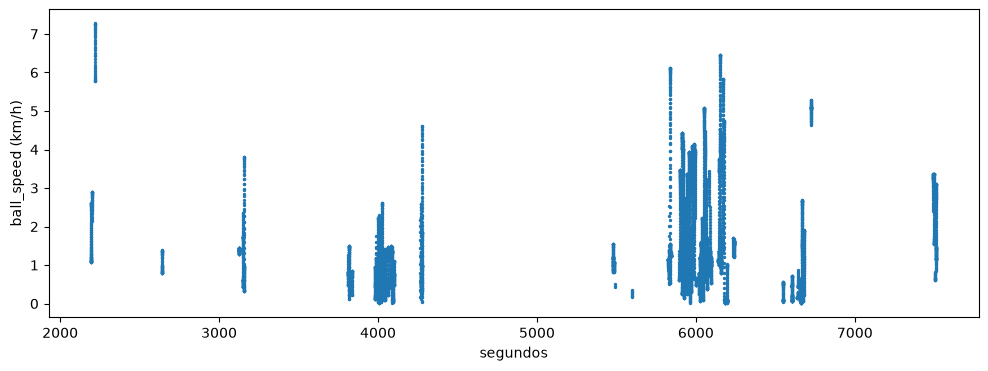

In [24]:
subset = frame_df[
    frame_df["ball_x"].notna()
    & frame_df["ball_y"].notna()
    & frame_df["ball_speed"].notna()
]
plt.figure(figsize=(12, 4))
plt.scatter((subset["frame_id"] - 1) / 25, subset["ball_speed"], s=2)
plt.xlabel("segundos")
plt.ylabel("ball_speed (km/h)")
plt.show()

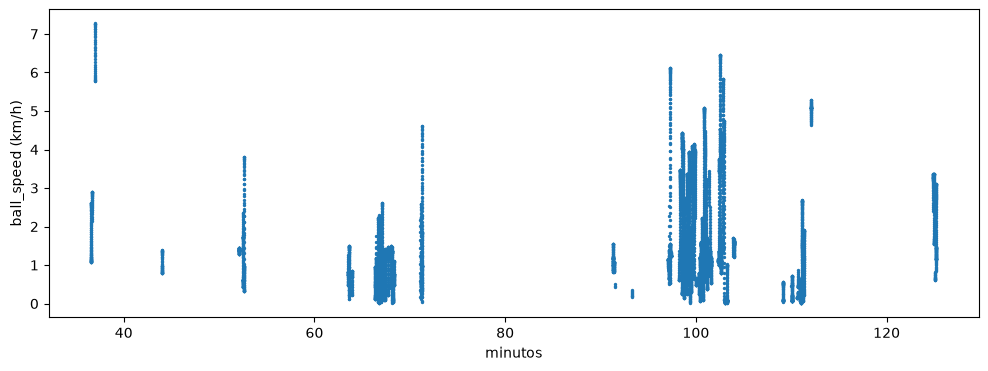

In [25]:
subset = frame_df[
    frame_df["ball_x"].notna()
    & frame_df["ball_y"].notna()
    & frame_df["ball_speed"].notna()
]
plt.figure(figsize=(12, 4))
plt.scatter((subset["frame_id"] - 1) / (25 * 60), subset["ball_speed"], s=2)
plt.xlabel("minutos")
plt.ylabel("ball_speed (km/h)")
plt.show()

## Compute own ball speed

In [27]:
L, W, fps = 105.3, 68.0, 25

In [28]:
dx = frame_df["ball_x"].diff() * L
dy = frame_df["ball_y"].diff() * W
seen = frame_df["ball_x"].notna() & frame_df["ball_y"].notna()

In [29]:
frame_df["ball_speed_mps"] = np.hypot(dx, dy) * fps
frame_df.loc[~(seen & seen.shift(fill_value=False)), "ball_speed_mps"] = np.nan

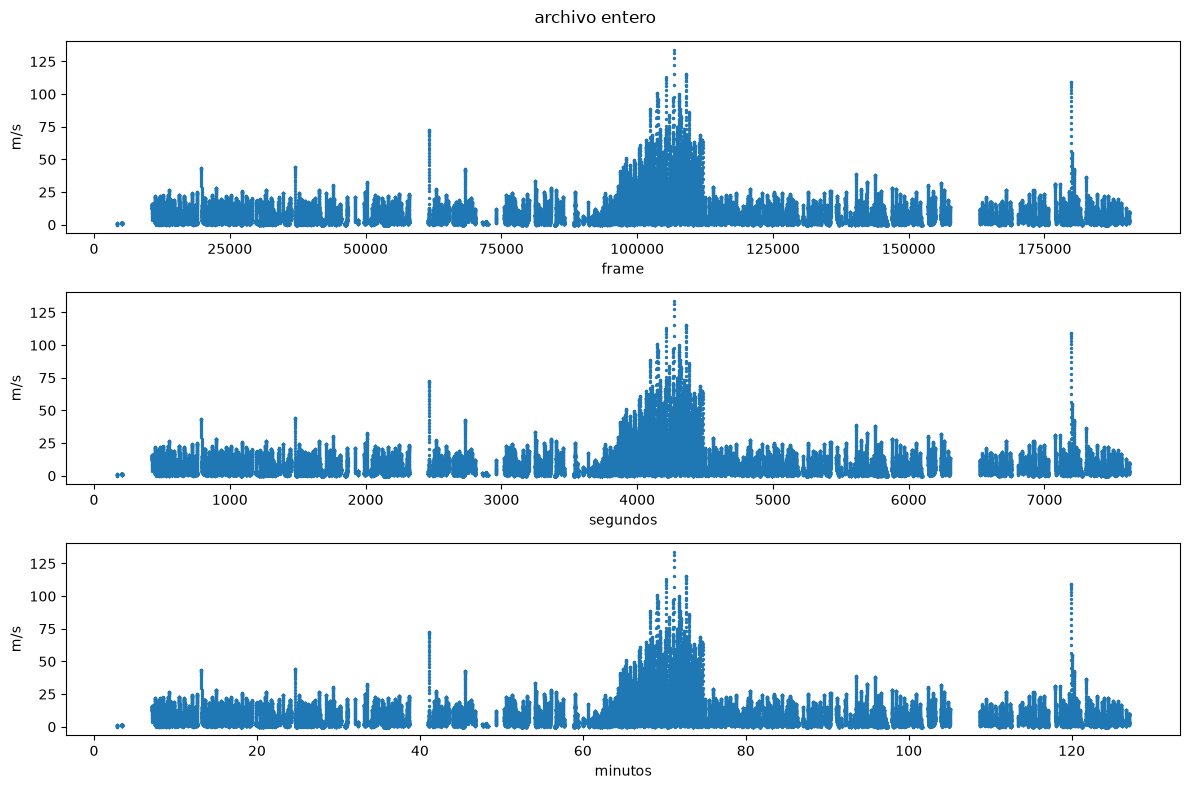

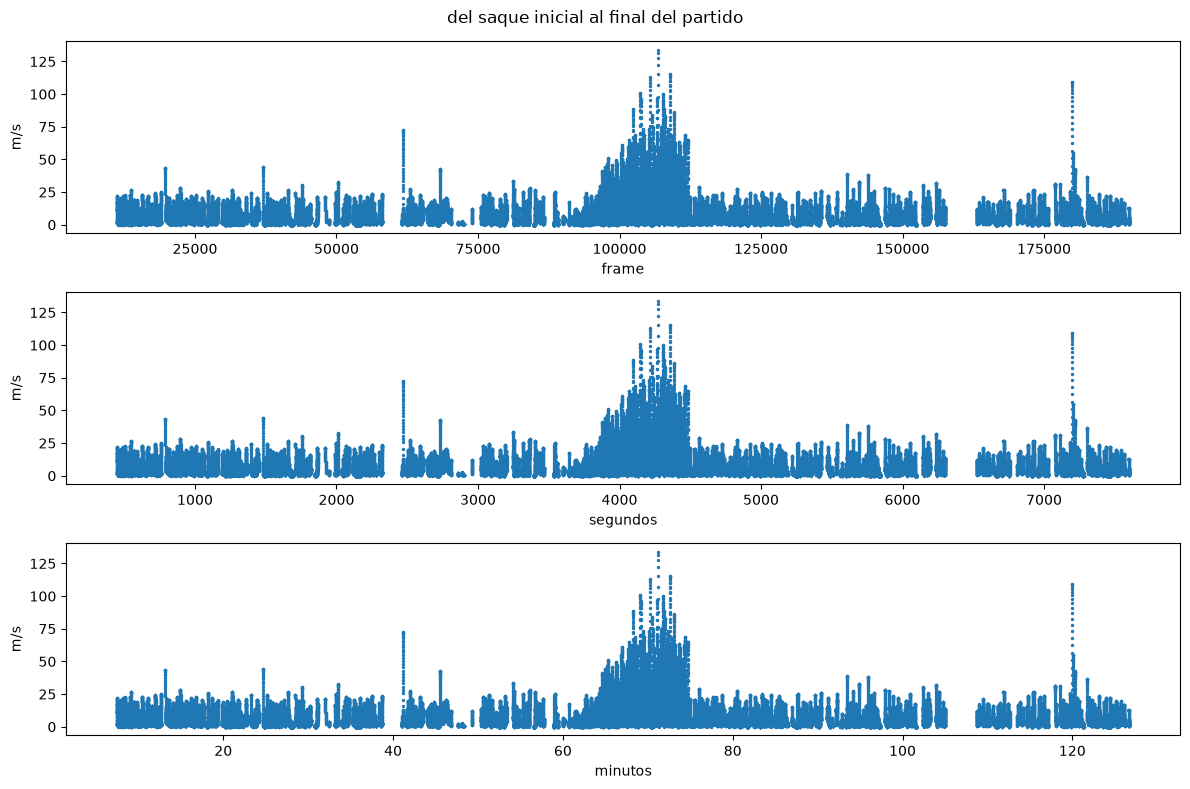

In [30]:
def plot_speed(df, title):
    part = df.loc[df["ball_speed_mps"].notna()]
    video_frame = part["frame_id"] - 1
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharey=True)
    for ax, x, label in zip(
        axes,
        (video_frame, video_frame / 25, video_frame / (25 * 60)),
        ("frame", "segundos", "minutos"),
    ):
        ax.scatter(x, part["ball_speed_mps"], s=2)
        ax.set_xlabel(label)
        ax.set_ylabel("m/s")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


plot_speed(frame_df, "archivo entero")

# Saque inicial de la primera parte (11185) hasta el último frame puntuado (190197).
# El descanso queda en medio y casi no tiene puntos.
video_frame = frame_df["frame_id"] - 1
play = frame_df[video_frame.between(11185, 190197)]
plot_speed(play, "del saque inicial al final del partido")

## Players tracker

In [31]:
frame_df

,period_id,timestamp,frame_id,ball_state,ball_owning_team_id,ball_x,ball_y,ball_z,ball_speed,1_x,...,44_s,45_x,45_y,45_d,45_s,46_x,46_y,46_d,46_s,ball_speed_mps
0,1,0 days 00:00:00.040000,1,None,None,NaN,NaN,None,NaN,0.33411,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,NaN
1,1,0 days 00:00:00.080000,2,None,None,NaN,NaN,None,NaN,0.33404,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,NaN
2,1,0 days 00:00:00.120000,3,None,None,NaN,NaN,None,NaN,0.33396,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,NaN
3,1,0 days 00:00:00.160000,4,None,None,NaN,NaN,None,NaN,0.33389,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,NaN
4,1,0 days 00:00:00.200000,5,None,None,NaN,NaN,None,NaN,0.33382,...,NaN,NaN,NaN,None,NaN,0.06057,0.39965,None,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199314,1,0 days 02:12:52.600000,199315,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,NaN
199315,1,0 days 02:12:52.640000,199316,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,NaN
199316,1,0 days 02:12:52.680000,199317,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,NaN
199317,1,0 days 02:12:52.720000,199318,None,None,NaN,NaN,None,NaN,NaN,...,NaN,NaN,NaN,None,NaN,0.96168,0.51646,None,NaN,NaN


In [33]:
x_cols = [f"{i}_x" for i in range(1, 47)]
s_cols = [f"{i}_s" for i in range(1, 47)]

In [34]:
frame_df["n_players"] = frame_df[x_cols].notna().sum(axis=1)
frame_df["n_players_speed"] = frame_df[s_cols].notna().sum(axis=1)

In [36]:
# cut just match:
video_frame = frame_df["frame_id"] - 1
play = frame_df[video_frame.between(11185, 190197)]

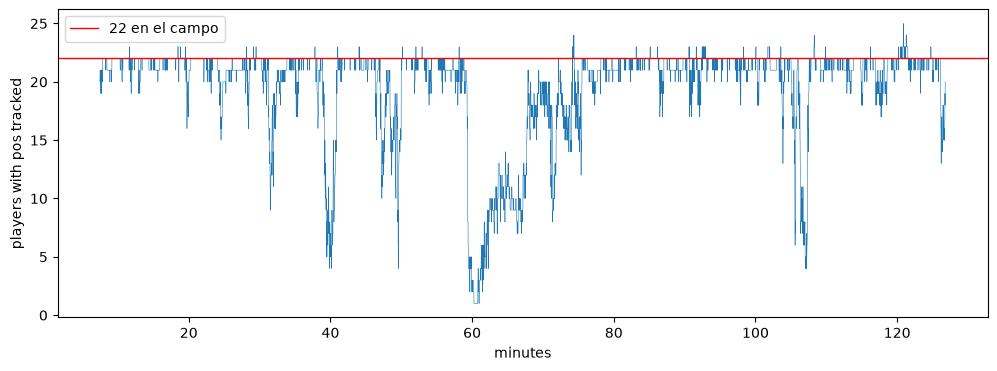

In [39]:
plt.figure(figsize=(12, 4))
plt.plot(video_frame.loc[play.index] / (25 * 60), play["n_players"], lw=0.4)
plt.axhline(22, color="red", lw=1, label="22 en el campo")
plt.xlabel("minutes")
plt.ylabel("players with pos tracked")
plt.legend()
plt.show()

In [40]:
n = len(play)
print("match frames: %d" % n)
print("fewer than 22: %d (%.1f%%)" % ((play["n_players"] < 22).sum(), 100 * (play["n_players"] < 22).mean()))
print("exactly 22: %d (%.1f%%)" % ((play["n_players"] == 22).sum(), 100 * (play["n_players"] == 22).mean()))
print("more than 22: %d (%.1f%%)" % ((play["n_players"] > 22).sum(), 100 * (play["n_players"] > 22).mean()))
print("22 or more: %d (%.1f%%)" % ((play["n_players"] >= 22).sum(), 100 * (play["n_players"] >= 22).mean()))
print("mean players with a position: %.2f" % play["n_players"].mean())
print("mean players with a speed: %.2f" % play["n_players_speed"].mean())

match frames: 179013
fewer than 22: 96658 (54.0%)
exactly 22: 78606 (43.9%)
more than 22: 3749 (2.1%)
22 or more: 82355 (46.0%)
mean players with a position: 19.59
mean players with a speed: 17.94


From players tracked positions at first glance we can understand something happend on minutes 30 aprox, 40, 50, and more pronunciated at 60 minute and 110 aprox.

## Baseline summary

El baseline hace dos cosas y se para ahí. En cada frame en el que ve el balón, se lo da al equipo del jugador más cercano. Si el balón es NaN, escribe D. 

Luego suaviza con un voto de mayoría: las variantes son ±0, ±25, ±50 y ±125 frames, es decir 0, 1, 2 y 5 segundos.

En el partido entero gana ±50, con spellF1 0.2433. Ese es el suelo. 

Confunde "no veo el balón" con "balón muerto" y no usa el Smart Tagging ni la estructura de una posesión.

### Propuestas

El baseline hace dos cosas y se para ahí. En cada frame en el que ve el balón, se lo da al equipo del jugador más cercano. Si el balón es NaN, escribe D. Luego suaviza con un voto de mayoría: las variantes son ±0, ±25, ±50 y ±125 frames, es decir 0, 1, 2 y 5 segundos. En el partido entero gana ±50, con spellF1 0.2433. Ese es el suelo. Confunde "no veo el balón" con "balón muerto" y no usa el Smart Tagging ni la estructura de una posesión.

Con los papers y con lo que ya hemos visto en los archivos, el siguiente algoritmo es una máquina de estados. En memoria van la etiqueta actual (H, A o D) y el último equipo que tuvo el balón en juego.

1. Con balón visible, la zona de Vidal-Codina, la que implementa DataBallPy. Radio 1,5 m. Solo cambia de equipo si el balón entra en la zona de un jugador durante varios frames y además cambia de velocidad o de dirección (umbral 5 m/s y 10°). Un balón que pasa por encima no es un control. Si hay dos rivales en la zona, es un duelo y se queda el último equipo. Link es la variante más simple: el más cercano por debajo de un umbral, y la acción se acaba si con esa velocidad no lo alcanza en 1 segundo.

2. La velocidad se calcula de ball_x y ball_y, en m/s, solo entre dos frames seguidos con posición. La columna ball_speed del archivo no sigue ese desplazamiento, así que no entra en la decisión. La s de los jugadores sí coincide con su propio desplazamiento y puede servir para ver si alguien está parado.

3. Si el balón es NaN, se mantiene el estado. No se escribe D. El hueco corto se puede puente con la última posición y la última velocidad. El hueco largo sigue siendo del último equipo.

4. D sale de las ventanas SET PIECES y de la geometría, no de la ausencia del balón. El tag dice dónde buscar el reinicio. El frame y el equipo salen de las posiciones: todos en su mitad y uno en el centro, gente en el córner, alguien en la banda. En los saques de banda Team es N/A, así que el equipo lo da quién está en la línea. Se sale de D cuando alguien vuelve a controlar el balón. Las otras fases (PROGRESSION, LONG BALL, GOALS) no se copian como etiqueta.

5. Los huecos con más de 22 jugadores se miran después, por si el tracker ha duplicado a alguien. No cambian la regla de posesión. La media que ya sale en el notebook, por debajo de 22, encaja con lo que dice DATA.md: durante el juego se ven unos 20,5 objetos.

Los radios se quedan en 1,5 m, 5 m/s y 10°. El mail prohíbe ajustarlos con los 5 minutos públicos o con este vídeo.

### Implementación

El orden es de menos piezas a más, y cada paso deja un CSV del partido entero. Los diagnósticos del notebook ya están hechos: ball_speed_mps y n_players.

1. Sustituir el D del baseline. El jugador más cercano sigue igual. Donde el balón es NaN, se repite el último equipo en juego en lugar de escribir D. D solo queda fuera del partido (antes del 11185, el descanso y después del 190197). Este es el cambio que ataca el fallo gordo. Al terminar, validate_submission.py y una sola pasada de run_evaluation.py contra los 5 minutos, al lado de baseline_smooth50, para ver que el archivo no está roto.

2. Cambiar "el más cercano" por la zona de 1,5 m. Solo hay control si el balón está a menos de 1,5 m durante varios frames y ball_speed_mps pasa de 5 m/s o gira más de 10°. Si nadie cumple eso, se mantiene el último equipo. Sigue sin usar el Smart Tagging.

3. El duelo. Si en esa zona hay un jugador de cada equipo, no se cambia de equipo.

4. El hueco corto. Si faltan menos de 0,5–1 s de balón, se alarga la última posición con la última velocidad y el paso 2 puede seguir decidiendo. Si el hueco es más largo, se mantiene el equipo y no se inventa una posición.
5. El D de verdad, con SET PIECES. La ventana dice dónde buscar. El frame y el equipo salen de las posiciones: saque de centro, córner, saque de puerta, banda. En los saques de banda el equipo lo da quién está en la línea, porque Team es N/A. Se vuelve a H o A cuando el paso 2 vuelve a ver un control.

6. Los frames con más de 22 jugadores, al final. Solo para ver si dos huecos son la misma persona. No entra en la regla hasta que los cinco pasos anteriores estén escritos.

En los pasos 2 y 3 los números se quedan fijos: 1,5 m, 5 m/s, 10°. No se mueven para que los 5 minutos queden mejor.

## Step 1 — nearest player, hold the last team

- Same decision as the baseline when the ball is visible. 
- A missing ball keeps the last in-play team instead of writing `D`. `D` is used before the match, through halftime and after the final whistle. 
- Each half starts with no team in memory, so possession does not cross the break. Fixed rules, not tuned on the public 5 minutes.

In [41]:
from baseline import write_submission
from load_smart_tagging import load as load_events

In [43]:
L, W, FPS = 105.3, 68.0, 25
PZ_RADIUS = 1.5
MIN_FRAMES = 3
ANGLE_DEG = 10.0
SPEED_DELTA = 5.0
SHORT_GAP = 25  # 1 second

In [44]:
video = frame_df["frame_id"].to_numpy() - 1
n = len(video)
in_play = ((video >= 11185) & (video <= 90651)) | ((video >= 110808) & (video <= 190197))
half_start = (video == 11185) | (video == 110808)

bx = frame_df["ball_x"].to_numpy(dtype=float)
by = frame_df["ball_y"].to_numpy(dtype=float)
px = frame_df[[f"{i}_x" for i in range(1, 47)]].to_numpy(dtype=float)
py = frame_df[[f"{i}_y" for i in range(1, 47)]].to_numpy(dtype=float)

In [45]:
def distances(ball_x, ball_y):
    dist = np.hypot(px * L - ball_x[:, None] * L, py * W - ball_y[:, None] * W)
    dist[~np.isfinite(px)] = np.inf
    return dist


def bridge_ball(ball_x, ball_y):
    """Fill gaps of at most 1 s with the last velocity, and only while the ball stays near the pitch."""
    out_x, out_y = ball_x.copy(), ball_y.copy()
    vx = np.full(n, np.nan)
    vy = np.full(n, np.nan)
    pair = (np.isfinite(ball_x[1:]) & np.isfinite(ball_x[:-1])
            & np.isfinite(ball_y[1:]) & np.isfinite(ball_y[:-1]))
    vx[1:][pair] = (ball_x[1:] - ball_x[:-1])[pair] * L * FPS
    vy[1:][pair] = (ball_y[1:] - ball_y[:-1])[pair] * W * FPS
    filled = 0
    i = 0
    while i < n:
        if np.isfinite(ball_x[i]):
            i += 1
            continue
        j = i
        while j < n and not np.isfinite(ball_x[j]):
            j += 1
        if 0 < (j - i) <= SHORT_GAP and i > 0 and np.isfinite(vx[i - 1]):
            sx, sy = vx[i - 1] / FPS, vy[i - 1] / FPS
            last_x, last_y = ball_x[i - 1], ball_y[i - 1]
            for k in range(j - i):
                nx = last_x + (k + 1) * sx / L
                ny = last_y + (k + 1) * sy / W
                if not (-0.05 <= nx <= 1.05 and -0.05 <= ny <= 1.05):
                    break
                out_x[i + k] = nx
                out_y[i + k] = ny
                filled += 1
        i = j
    return out_x, out_y, filled


def gain_mask(ball_x, ball_y):
    """A touch: the ball slows under 5 m/s, its speed changes by more than 5 m/s, or it turns more than 10 degrees."""
    speed = np.full(n, np.nan)
    vx = np.full(n, np.nan)
    vy = np.full(n, np.nan)
    pair = (np.isfinite(ball_x[1:]) & np.isfinite(ball_x[:-1])
            & np.isfinite(ball_y[1:]) & np.isfinite(ball_y[:-1]))
    vx[1:][pair] = (ball_x[1:] - ball_x[:-1])[pair] * L * FPS
    vy[1:][pair] = (ball_y[1:] - ball_y[:-1])[pair] * W * FPS
    speed[1:][pair] = np.hypot(vx[1:][pair], vy[1:][pair])
    angle = np.degrees(np.arctan2(vy, vx))
    turn = np.zeros(n)
    both = np.isfinite(angle[1:]) & np.isfinite(angle[:-1])
    raw = np.abs(np.diff(angle))
    turn[1:][both] = np.minimum(raw, 360 - raw)[both]
    delta = np.zeros(n)
    both_s = np.isfinite(speed[1:]) & np.isfinite(speed[:-1])
    delta[1:][both_s] = np.abs(np.diff(speed))[both_s]
    return (turn > ANGLE_DEG) | (delta > SPEED_DELTA) | (np.isfinite(speed) & (speed < SPEED_DELTA))


def spell_count(labels):
    count = 0
    previous = None
    for label in labels:
        if label in ("H", "A") and label != previous:
            count += 1
        previous = None if label == "D" else label
    return count


def write_labels(name, labels):
    path = os.path.join("..", "evaluation", "results", name + ".csv")
    write_submission(path, labels)
    counts = {label: int((labels == label).sum()) for label in "HAD"}
    print(name, counts, "possessions", spell_count(labels))
    return labels


def run_possession(name, use_zone=False, use_duel=False, use_bridge=False, use_pieces=False):
    ball_x, ball_y = bx, by
    if use_bridge:
        ball_x, ball_y, filled = bridge_ball(bx, by)
        print("bridged frames", filled)
    dist = distances(ball_x, ball_y)
    here = np.isfinite(ball_x) & np.isfinite(ball_y)
    gain = gain_mask(ball_x, ball_y)
    nearest = np.argmin(dist, axis=1)
    nearest_dist = dist[np.arange(n), nearest]

    piece = np.zeros(n, dtype=np.int32)
    piece_team = np.full(n, "?", dtype="<U1")
    if use_pieces:
        piece_id = 1
        for event in load_events():
            if event["code"] != "SET PIECES":
                continue
            start = max(0, event["start_frame"])
            end = min(n, event["end_frame"])
            team = {"Barcelona": "H", "Atletic Club": "A"}.get(event["tags"].get("Team"), "?")
            piece[start:end] = piece_id
            piece_team[start:end] = team
            piece_id += 1

    labels = np.full(n, "D", dtype="<U1")
    last = None
    streak = 0
    streak_team = None
    active_piece = 0
    released = True

    for i in range(n):
        if half_start[i]:
            last = None
            streak = 0
            streak_team = None
        if not in_play[i]:
            continue

        def team_in_zone():
            home = np.any(dist[i, :24] <= PZ_RADIUS)
            away = np.any(dist[i, 24:] <= PZ_RADIUS)
            if home and away:
                if use_duel:
                    return "duel"
                inside = np.flatnonzero(dist[i] <= PZ_RADIUS)
                slot = inside[np.argmin(dist[i, inside])]
                return "H" if slot < 24 else "A"
            if home or away:
                return "H" if home else "A"
            return None

        if use_pieces and piece[i] != active_piece:
            active_piece = int(piece[i])
            released = active_piece == 0
            streak = 0
            streak_team = None
        if use_pieces and active_piece and not released:
            team = team_in_zone() if here[i] else None
            if team in ("H", "A"):
                streak = streak + 1 if team == streak_team else 1
                streak_team = team
            else:
                streak = 0
                streak_team = None
            wanted = piece_team[i]
            if team in ("H", "A") and streak >= MIN_FRAMES and gain[i] and wanted in ("?", team):
                released = True
                last = team
                labels[i] = team
            continue

        if not here[i] or not np.isfinite(nearest_dist[i]):
            if last:
                labels[i] = last
            streak = 0
            streak_team = None
            continue

        if not use_zone:
            last = "H" if nearest[i] < 24 else "A"
            labels[i] = last
            continue

        team = team_in_zone()
        if team == "duel" or team is None:
            if last:
                labels[i] = last
            streak = 0
            streak_team = None
            continue
        streak = streak + 1 if team == streak_team else 1
        streak_team = team
        if streak >= MIN_FRAMES and gain[i]:
            last = team
        labels[i] = last if last else "D"

    return write_labels(name, labels)


labels_step1 = run_possession("step1_hold")

step1_hold {'H': 87272, 'A': 71583, 'D': 40464} possessions 1863


## Step 2 — possession zone

- A team takes the ball only when it is the side inside 1.5 m for 3 frames and the ball is touched: it slows under 5 m/s, its speed changes by more than 5 m/s, or it turns more than 10°.
- A ball that only passes through the zone does not switch the team. If both teams are inside t he zone, the closest player gets it.
- This is the Vidal-Codina / DataBallPy rule with the published constants.

In [46]:
labels_step2 = run_possession("step2_zone", use_zone=True)

step2_zone {'H': 89972, 'A': 68530, 'D': 40817} possessions 326


## Step 3 — duels

When one player from each team is inside the 1.5 m zone, the ball stays with the last team. A loose ball is not a change of possession.

In [47]:
labels_step3 = run_possession("step3_duel", use_zone=True, use_duel=True)

step3_duel {'H': 87312, 'A': 71190, 'D': 40817} possessions 271


## Step 4 — short gaps

If the ball disappears for at most 1 second, its last velocity is extended and the zone rule can still fire. Longer gaps keep the last team and do not invent a position. The file's `ball_speed` column is not used.

In [48]:
labels_step4 = run_possession("step4_bridge", use_zone=True, use_duel=True, use_bridge=True)

bridged frames 183
step4_bridge {'H': 87361, 'A': 71141, 'D': 40817} possessions 271


## Step 5 — dead ball from set pieces

- Each `SET PIECES` window is a place to look, not a label. 
- From the start of the window the label is `D` until a team controls the ball again under the zone rule.
- If the tag names Barcelona or Athletic, only that team can end the dead ball.
- Throw-ins are `N/A`, so the team is whoever wins the zone. Other phase codes are not copied onto the labels.


The CSVs land in `evaluation/results/`. One run of `python evaluation/run_evaluation.py` compares them with `baseline_smooth50` on the public 5 minutes. That check is for a broken file, not for changing the radii.

In [49]:
labels_step5 = run_possession(
    "step5_set_pieces", use_zone=True, use_duel=True, use_bridge=True, use_pieces=True
)

bridged frames 183
step5_set_pieces {'H': 80285, 'A': 65032, 'D': 54002} possessions 298


## Public 5-minute comparison

Reads `evaluation/scoreboard.csv`, written by `run_evaluation.py`. Every row is that file scored on the same 7,500 graded frames. `spell_f1_mean` is the ranking number. The truth in this window has 17 possessions. This is a pipeline check: on these 5 minutes `baseline_smooth125` beats `baseline_smooth50`, and on the full match it is the other way around.

In [50]:
import pandas as pd

board = pd.read_csv(os.path.join("..", "evaluation", "scoreboard.csv"))
keep = [
    "step1_hold", "step2_zone", "step3_duel", "step4_bridge", "step5_set_pieces",
    "baseline_raw", "baseline_smooth25", "baseline_smooth50", "baseline_smooth125",
]
compare = board.loc[board["submission"].isin(keep)].copy()
compare = compare.sort_values("spell_f1_mean", ascending=False)

columns = [
    "submission", "spell_f1_mean", "macro_f1",
    "poss", "n_gt_spells", "dur", "gt_mean_spell_duration_s",
    "f1_H", "f1_A", "f1_D",
]
compare[columns]

,submission,spell_f1_mean,macro_f1,poss,n_gt_spells,dur,gt_mean_spell_duration_s,f1_H,f1_A,f1_D
0,step5_set_pieces,0.475676,0.617473,20,17,13.912000,14.190588,0.801775,0.747613,0.303030
1,baseline_smooth125,0.424242,0.581185,16,17,18.460000,14.190588,0.786414,0.810770,0.146372
2,step2_zone,0.400000,0.510319,24,17,12.113333,14.190588,0.760111,0.770845,0.000000
3,step3_duel,0.400000,0.503958,18,17,16.151111,14.190588,0.802097,0.709776,0.000000
4,step4_bridge,0.400000,0.503958,18,17,16.151111,14.190588,0.802097,0.709776,0.000000
5,baseline_smooth50,0.325581,0.620733,26,17,10.803077,14.190588,0.778147,0.761505,0.322548
6,baseline_smooth25,0.286792,0.619991,36,17,7.580000,14.190588,0.762016,0.712302,0.385654
7,step1_hold,0.044138,0.472226,128,17,2.343125,14.190588,0.683284,0.733394,0.000000
8,baseline_raw,0.037838,0.597227,131,17,2.019847,14.190588,0.728960,0.643011,0.419711


- baseline 125 es el mejor resultado en los 5 mins publicos
- baseline smooth 50 es el mejor en el archivo enter

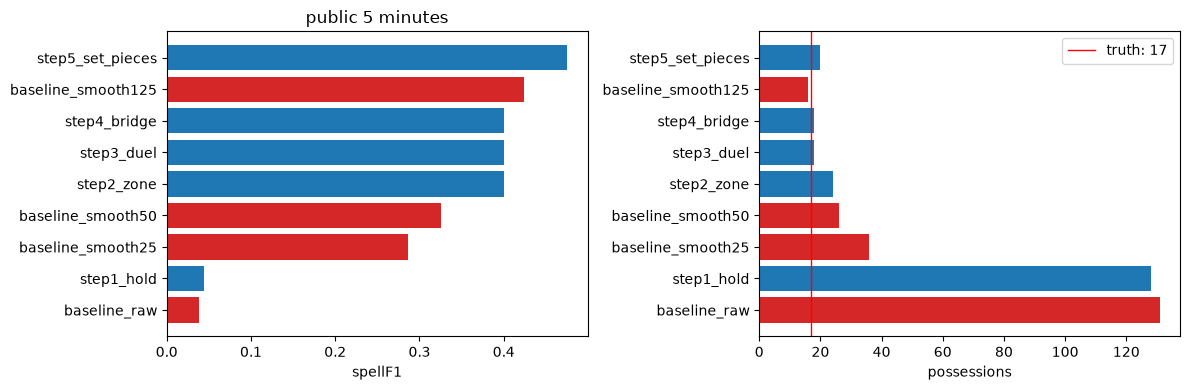

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

order = compare.sort_values("spell_f1_mean")
colors = ["#d62728" if name.startswith("baseline") else "#1f77b4" for name in order["submission"]]
axes[0].barh(order["submission"], order["spell_f1_mean"], color=colors)
axes[0].set_xlabel("spellF1")
axes[0].set_title("public 5 minutes")

axes[1].barh(order["submission"], order["poss"], color=colors)
axes[1].axvline(order["n_gt_spells"].iloc[0], color="red", lw=1, label="truth: 17")
axes[1].set_xlabel("possessions")
axes[1].legend()

fig.tight_layout()
plt.show()

## First mismatch on the pitch

The first non-matched row in `step5_set_pieces_transitions.csv`. The animation is the tracking, two seconds around that frame, same drawing as notebook 2.

In [54]:
from IPython.display import HTML
from utils import animate_frames, plot_frame

In [58]:
transitions = pd.read_csv(os.path.join("..", "evaluation", "reports", "step5_set_pieces_transitions.csv"))
first = transitions.loc[transitions["status"] != "matched"].iloc[0]
frame = int(first["gt_frame"] if first["status"] == "missed" else first["pred_frame"])

Estado	Qué es	En step5
- **matched**. La verdad cambia y step5 cambia al mismo destino, dentro de esos 25 frames. latency es pred_frame - gt_frame. 4
- **missed**. La verdad cambia y step5 no tiene un cambio al mismo destino en esa ventana. Solo vienen gt_frame, gt_from, gt_to. 16
- **spurious** Step5 cambia y no hay un cambio real al mismo destino cerca. Solo vienen pred_frame, pred_from, pred_to.18

In [59]:
transitions

,status,gt_frame,pred_frame,latency,gt_from,gt_to,pred_from,pred_to
0,missed,11351.0,NaN,NaN,A,H,NaN,NaN
1,spurious,NaN,11417.0,NaN,NaN,NaN,D,A
2,spurious,NaN,11479.0,NaN,NaN,NaN,A,H
3,missed,11553.0,NaN,NaN,H,A,NaN,NaN
4,missed,11624.0,NaN,NaN,A,H,NaN,NaN
5,spurious,NaN,11708.0,NaN,NaN,NaN,H,A
6,spurious,NaN,11800.0,NaN,NaN,NaN,A,H
7,spurious,NaN,12441.0,NaN,NaN,NaN,H,A
8,spurious,NaN,12483.0,NaN,NaN,NaN,A,H
9,missed,12665.0,NaN,NaN,H,A,NaN,NaN


status         missed
gt_frame      11351.0
pred_frame        NaN
latency           NaN
gt_from             A
gt_to               H
pred_from         NaN
pred_to           NaN
frame 11351 second 454.04
truth H step5 D


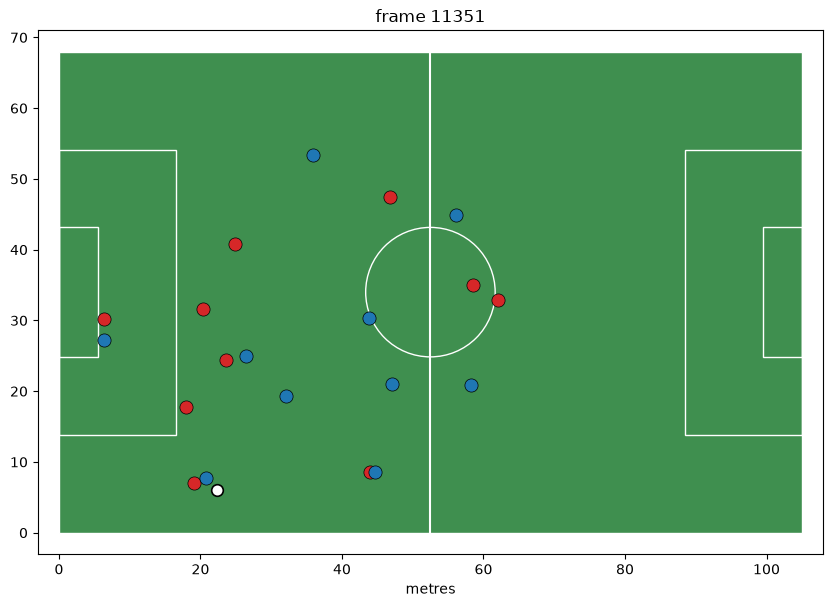

In [61]:
gt = pd.read_csv(os.path.join("..", "evaluation", "gt", "BAR-ATH_possession_gt_public.csv"))
pred = pd.read_csv(os.path.join("..", "evaluation", "results", "step5_set_pieces.csv"))
print(first.to_string())
print("frame", frame, "second", round(frame / 25, 2))
print("truth", gt.loc[gt["frame"] == frame, "label"].iloc[0],
      "step5", pred.loc[pred["frame"] == frame, "label"].iloc[0])

plot_frame(dataset, frame)
plt.show()

HTML(animate_frames(dataset, frame - 25, frame + 25).to_jshtml())

In [62]:
# Same two seconds as the animation. Pauses on the mismatch frame.
# Run this from more-than-a-hack-2027-main, not from the notebook.
# Space continues. Left and right arrows move one frame.
print("cd ..")
print("python play_clip.py %d %d %d" % (frame - 25, frame + 25, frame))

cd ..
python play_clip.py 11326 11376


falta en el frame df ir calucaldno los steps por pasos y marcar el estado de cada cosa para entedner cmabio y porque